# Data-Driven Imputation of Missing Economic Indicators for EU Regions: A Multi-Metric Accuracy Assessment

## Notebook 1 – Baseline models

**Authors:** Irmantas Pilypas, Irma Šileikienė
**Institution:** Vilnius University Šiauliai Academy

---

## Study description

This study examines the effectiveness of the XGBoost and Random Forest algorithms for imputing missing economic indicator values at the EU NUTS 2 regional level. Separate Random Forest and XGBoost models are developed for each economic indicator, and imputation accuracy is evaluated using the nRMSE, nMAE, R² and sMAPE metrics with five-fold cross-validation.

This notebook implements the **baseline** experiment: Random Forest and XGBoost models with the baseline (main) hyperparameter configuration, evaluated with five-fold cross-validation.

**Article outputs reproduced in this notebook:**
- Table 1 – Economic indicators and percentage of missing values by indicator
- Figure 1 – Correlation matrix of economic indicators at the NUTS 2 regional level
- Figure 2 – Missingness matrix of economic indicators at the NUTS 2 regional level
- Table 2 – Baseline Random Forest and XGBoost model performance metrics (nRMSE, nMAE, R²) using 5-fold cross-validation
- Table 4 – Overall cross-validation performance of baseline imputation models
- Figure 5 – nRMSE and nMAE error distribution for baseline Random Forest and XGBoost models (youth unemployment rate, ROD5)

The cross-validation metrics are saved to `results/cv_metrics_baseline.csv`; they are used by Notebook 2 to produce Figure 4.

**Data:**
- **260** NUTS 2 regions
- **8** economic indicators (ROD1–ROD8)
- **Period:** 1990–2023
- **Total:** 6,984 observations
- **Source:** Eurostat

**Evaluation metrics** (Equations (3)–(6) of the article):

$$nRMSE = \frac{\sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2}}{y_{max}-y_{min}} \qquad
nMAE = \frac{\frac{1}{n}\sum_{i=1}^{n}\left|y_i-\hat{y}_i\right|}{y_{max}-y_{min}}$$

$$R^2 = 1-\frac{\sum_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2}{\sum_{i=1}^{n}\left(y_i-\bar{y}\right)^2} \qquad
sMAPE = \frac{100\%}{n}\sum_{i=1}^{n}\frac{\left|y_i-\hat{y}_i\right|}{\left(\left|y_i\right|+\left|\hat{y}_i\right|\right)/2}$$

where $y_i$ is the actual value of the $i$-th observation, $\hat{y}_i$ is the predicted value, $\bar{y}$ is the mean of the actual values and $n$ is the number of observations. nRMSE and nMAE are normalized by the range of the actual values in each validation fold.

## 1. Environment setup

The study is conducted in Python with the scikit-learn and xgboost libraries. The Random Forest and XGBoost imputation models are implemented in the `imputation_models/` package.

> **Reproducibility note.** The results reported in the article were obtained with **xgboost ≥ 3.0** (scikit-learn 1.5.2). Earlier xgboost versions (e.g. 2.x) use different internal defaults and produce slightly different XGBoost metrics. The exact package versions are listed in `requirements.txt`.

In [1]:
# ============================================================================
# LIBRARY IMPORTS
# ============================================================================

import os
import time
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import sklearn
import xgboost
from matplotlib.patches import Patch
from IPython.display import display

from imputation_models import RandomForestImputer, XGBoostImputer

# Configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_theme(font_scale=1.2)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.unicode_minus'] = False

# Output directories
RESULTS_DIR = 'results'
FIGURES_DIR = os.path.join(RESULTS_DIR, 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

print(f"Python:       {platform.python_version()}")
print(f"numpy:        {np.__version__}")
print(f"pandas:       {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"xgboost:      {xgboost.__version__}")

if int(xgboost.__version__.split('.')[0]) < 3:
    print("\nWARNING: xgboost < 3.0 detected. The XGBoost metrics may differ slightly "
          "from the values reported in the article (obtained with xgboost >= 3.0).")

Python:       3.11.9
numpy:        2.0.2
pandas:       2.2.3
scikit-learn: 1.5.2
xgboost:      3.1.3


## 2. Data loading and preparation

The NUTS 2 regional economic indicators dataset was compiled from the official database of the European Union Statistical Office (Eurostat). For more explicit indicator identification in the subsequent analysis, the indicators are denoted by the indices **ROD1–ROD8** (Table 1).

In [2]:
# ============================================================================
# DATA LOADING
# ============================================================================

DATA_PATH = os.path.join('uploads', 'nuts2_economic_indicators_2026-10-29.csv')

df_raw = pd.read_csv(DATA_PATH)

print(f"Data loaded: {len(df_raw):,} rows, {len(df_raw.columns)} columns")
print(f"Columns: {', '.join(df_raw.columns)}")
display(df_raw.head())

Data loaded: 6,984 rows, 10 columns
Columns: geo, year, employment_rate, rd_expenditure_pct_gdp, unemployment_rate, tertiary_education_pct, youth_unemployment_rate, population_density, long_term_unemployment_share, female_employment_rate


,geo,year,employment_rate,rd_expenditure_pct_gdp,unemployment_rate,tertiary_education_pct,youth_unemployment_rate,population_density,long_term_unemployment_share,female_employment_rate
0,AL01,2012,NaN,NaN,NaN,NaN,NaN,79.2,NaN,NaN
1,AL01,2013,NaN,NaN,NaN,NaN,NaN,78.5,NaN,NaN
2,AL01,2014,NaN,NaN,NaN,NaN,NaN,77.7,NaN,NaN
3,AL01,2015,NaN,NaN,NaN,NaN,NaN,77.0,NaN,NaN
4,AL01,2016,NaN,NaN,NaN,NaN,NaN,76.6,NaN,NaN


In [3]:
# ============================================================================
# INDICATOR IDENTIFIERS (ROD1-ROD8, Table 1)
# ============================================================================

INDICATORS = {
    'ROD1': 'employment_rate',
    'ROD2': 'rd_expenditure_pct_gdp',
    'ROD3': 'unemployment_rate',
    'ROD4': 'tertiary_education_pct',
    'ROD5': 'youth_unemployment_rate',
    'ROD6': 'population_density',
    'ROD7': 'long_term_unemployment_share',
    'ROD8': 'female_employment_rate',
}
INDICATOR_IDS = list(INDICATORS)

df = df_raw.rename(columns={name: ind_id for ind_id, name in INDICATORS.items()})

print("Indicator identifiers:")
for ind_id, name in INDICATORS.items():
    print(f"  {ind_id} = {name}")

print("\nDataset summary:")
print(f"  NUTS 2 regions:      {df['geo'].nunique()}")
print(f"  Period:              {df['year'].min()}-{df['year'].max()}")
print(f"  Observations:        {len(df):,}")
print(f"  Economic indicators: {len(INDICATOR_IDS)}")

Indicator identifiers:
  ROD1 = employment_rate
  ROD2 = rd_expenditure_pct_gdp
  ROD3 = unemployment_rate
  ROD4 = tertiary_education_pct
  ROD5 = youth_unemployment_rate
  ROD6 = population_density
  ROD7 = long_term_unemployment_share
  ROD8 = female_employment_rate

Dataset summary:
  NUTS 2 regions:      260
  Period:              1990-2023
  Observations:        6,984
  Economic indicators: 8


## 3. Exploratory data analysis

### 3.1 Missing values by indicator (Table 1)

The dataset contains a significant number of missing values, varying between indicators.

In [4]:
# ============================================================================
# TABLE 1. ECONOMIC INDICATORS AND PERCENTAGE OF MISSING VALUES BY INDICATOR
# ============================================================================

missing_pct = df[INDICATOR_IDS].isna().mean() * 100

table1 = pd.DataFrame({
    'Indicator ID': INDICATOR_IDS,
    'Indicator': [INDICATORS[i] for i in INDICATOR_IDS],
    'Missing values (%)': missing_pct.values,
})

print("Table 1. Economic indicators and percentage of missing values by indicator")
display(table1.style.hide(axis='index').format({'Missing values (%)': '{:.2f}'}))

total_cells = df[INDICATOR_IDS].size
total_missing = int(df[INDICATOR_IDS].isna().sum().sum())
print(f"Missing values in total: {total_missing:,} of {total_cells:,} ({total_missing / total_cells * 100:.2f}%)")
print(f"Range: {missing_pct.min():.2f}% ({INDICATORS[missing_pct.idxmin()]}) - "
      f"{missing_pct.max():.2f}% ({INDICATORS[missing_pct.idxmax()]})")

Table 1. Economic indicators and percentage of missing values by indicator


Indicator ID,Indicator,Missing values (%)
ROD1,employment_rate,28.15
ROD2,rd_expenditure_pct_gdp,53.81
ROD3,unemployment_rate,29.04
ROD4,tertiary_education_pct,29.70
ROD5,youth_unemployment_rate,36.78
ROD6,population_density,10.01
ROD7,long_term_unemployment_share,35.09
ROD8,female_employment_rate,28.15


Missing values in total: 17,511 of 55,872 (31.34%)
Range: 10.01% (population_density) - 53.81% (rd_expenditure_pct_gdp)


### 3.2 Correlation matrix (Figure 1)

To examine the interrelationships among the economic indicators, a correlation analysis is conducted. The correlation coefficients are reported in each cell; the variables are ordered by hierarchical clustering.

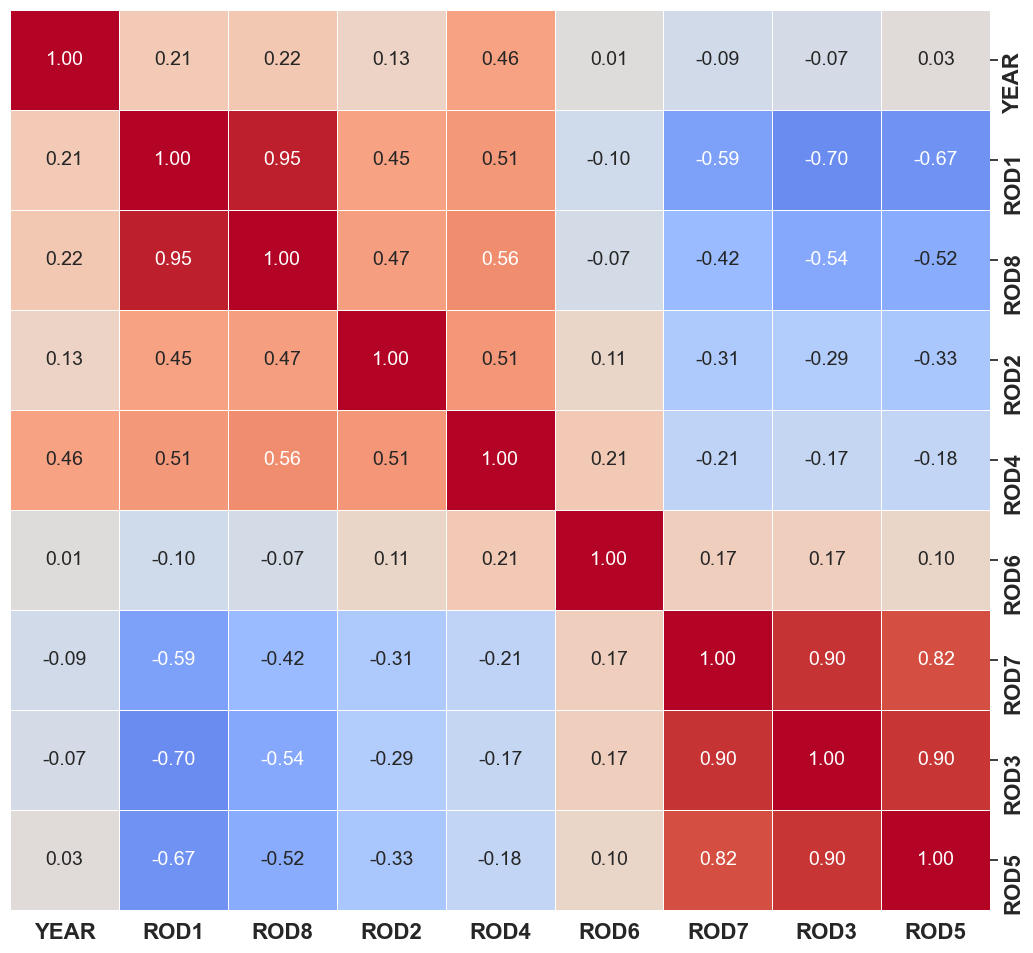

In [5]:
# ============================================================================
# FIGURE 1. CORRELATION MATRIX OF ECONOMIC INDICATORS
# ============================================================================

# Numeric columns with non-zero variance (year and ROD1-ROD8)
numeric_cols = df.select_dtypes(include=[np.number]).columns
numeric_cols = [col for col in numeric_cols if df[col].std() > 0]

# Pearson correlation matrix (pairwise complete observations)
corr = df[numeric_cols].corr().fillna(0)
corr_display = corr.rename(index={'year': 'YEAR'}, columns={'year': 'YEAR'})

g = sns.clustermap(
    corr_display,
    cmap="coolwarm",
    figsize=(13, 12),
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 14},
)
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.cax.set_visible(False)
g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")
plt.setp(g.ax_heatmap.get_xticklabels(), fontsize=16, fontweight='bold')
plt.setp(g.ax_heatmap.get_yticklabels(), fontsize=16, fontweight='bold')

g.savefig(os.path.join(FIGURES_DIR, 'figure_1_correlation_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()

In [6]:
# ============================================================================
# CORRELATION COEFFICIENTS DISCUSSED IN THE ARTICLE
# ============================================================================

pairs = [
    ('ROD1', 'ROD8', 'employment rate - female employment rate'),
    ('ROD3', 'ROD5', 'unemployment rate - youth unemployment rate'),
    ('ROD3', 'ROD7', 'unemployment rate - long-term unemployment share'),
    ('ROD5', 'ROD7', 'youth unemployment rate - long-term unemployment share'),
    ('ROD1', 'ROD3', 'employment rate - unemployment rate'),
    ('ROD1', 'ROD5', 'employment rate - youth unemployment rate'),
]

for a, b, description in pairs:
    print(f"  r({a}, {b}) = {corr.loc[a, b]:+.2f}   ({description})")

rod6 = corr.loc['ROD6', [c for c in INDICATOR_IDS if c != 'ROD6']]
print(f"\n  Population density (ROD6): |r| with the other indicators ranges from "
      f"{rod6.abs().min():.2f} to {rod6.abs().max():.2f}")

  r(ROD1, ROD8) = +0.95   (employment rate - female employment rate)
  r(ROD3, ROD5) = +0.90   (unemployment rate - youth unemployment rate)
  r(ROD3, ROD7) = +0.90   (unemployment rate - long-term unemployment share)
  r(ROD5, ROD7) = +0.82   (youth unemployment rate - long-term unemployment share)
  r(ROD1, ROD3) = -0.70   (employment rate - unemployment rate)
  r(ROD1, ROD5) = -0.67   (employment rate - youth unemployment rate)

  Population density (ROD6): |r| with the other indicators ranges from 0.07 to 0.21


### 3.3 Missingness mechanism (Figure 2)

Identifying the mechanism of missing data is essential for selecting appropriate imputation methods. The missingness matrix (Figure 2) shows structured and clustered patterns of missingness, particularly for R&D expenditure as a percentage of GDP (ROD2) and the youth unemployment rate (ROD5). The proportions of missing values vary considerably across indicators (Table 1), time periods and regions (charts below), which indicates that the missing values are unlikely to be Missing Completely at Random (MCAR); the observed patterns are largely consistent with the Missing at Random (MAR) assumption.

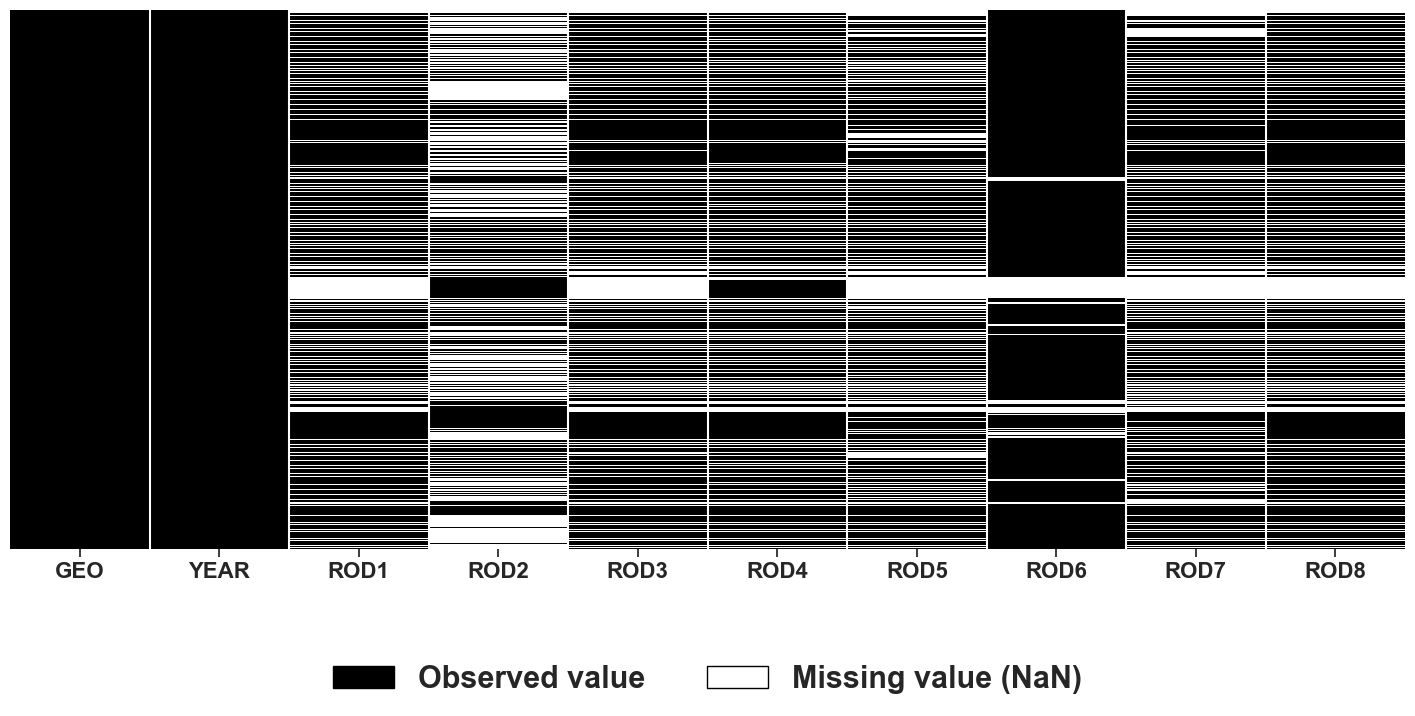

In [7]:
# ============================================================================
# FIGURE 2. MISSINGNESS MATRIX OF ECONOMIC INDICATORS
# ============================================================================

def plot_missingness_matrix(data):
    """Missingness matrix for all columns (black = observed value, white = missing value)."""
    msno.matrix(
        data,
        figsize=(18, 7),
        labels=True,
        sparkline=False,
        color=(0.0, 0.0, 0.0),
    )

    ax = plt.gca()
    ax.set_yticklabels([])
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='center', fontsize=16, fontweight='bold')
    ax.xaxis.tick_bottom()

    legend_elements = [
        Patch(facecolor="black", edgecolor="black", label="Observed value"),
        Patch(facecolor="white", edgecolor="black", label="Missing value (NaN)"),
    ]
    ax.legend(
        handles=legend_elements,
        loc="lower center",
        ncol=2,
        prop={'size': 22, 'weight': 'bold'},
        frameon=False,
        bbox_to_anchor=(0.5, -0.32),
    )
    return ax


ax = plot_missingness_matrix(df.rename(columns={'geo': 'GEO', 'year': 'YEAR'}))
ax.figure.savefig(os.path.join(FIGURES_DIR, 'figure_2_missingness_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()

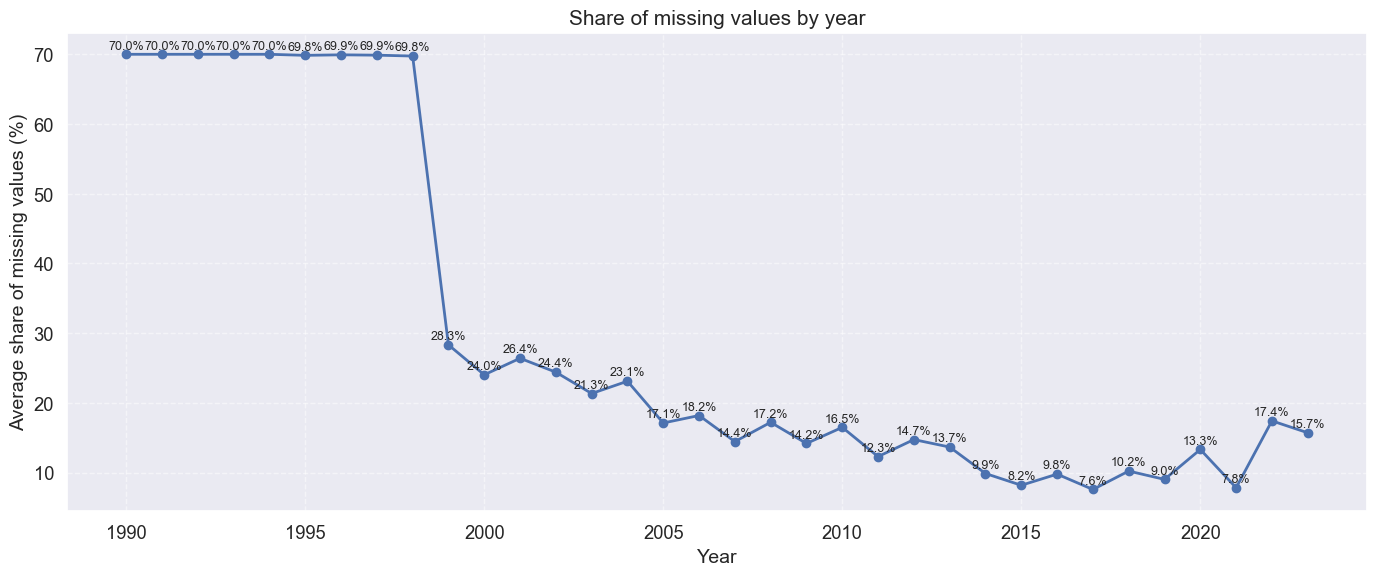

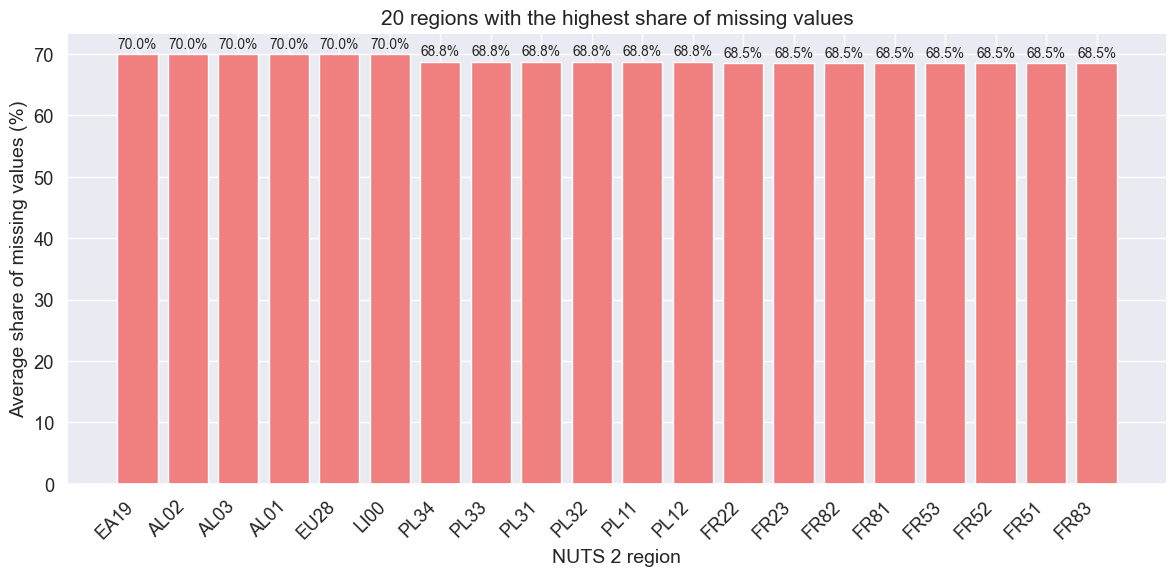

Share of missing values by year:   7.6% - 70.0%
Share of missing values by region: 3.2% - 70.0%


In [8]:
# ============================================================================
# SHARE OF MISSING VALUES BY YEAR AND BY REGION
# ============================================================================

# Average share of missing values in each year (%), computed over all columns
missing_by_year = df.groupby('year').apply(lambda x: x.isna().mean().mean()) * 100

plt.figure(figsize=(14, 6))
plt.plot(missing_by_year.index, missing_by_year.values, marker="o", linewidth=2)
plt.xlabel("Year", fontsize=14)
plt.ylabel("Average share of missing values (%)", fontsize=14)
plt.title("Share of missing values by year", fontsize=15)
plt.grid(True, linestyle="--", alpha=0.5)
for year, val in missing_by_year.items():
    plt.text(year, val + 0.8, f"{val:.1f}%", fontsize=9, ha="center")
plt.tight_layout()
plt.show()

# Average share of missing values in each region (%), 20 regions with the highest share
missing_by_region = df.groupby('geo').apply(lambda x: x.isna().mean().mean() * 100)
missing_by_region_top = missing_by_region.sort_values(ascending=False).head(20)

plt.figure(figsize=(12, 6))
plt.bar(missing_by_region_top.index, missing_by_region_top.values, color="lightcoral")
plt.ylabel("Average share of missing values (%)", fontsize=14)
plt.xlabel("NUTS 2 region", fontsize=14)
plt.title("20 regions with the highest share of missing values", fontsize=15)
plt.xticks(rotation=45, ha='right')
for region, val in missing_by_region_top.items():
    plt.text(region, val + 1, f"{val:.1f}%", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Share of missing values by year:   {missing_by_year.min():.1f}% - {missing_by_year.max():.1f}%")
print(f"Share of missing values by region: {missing_by_region.min():.1f}% - {missing_by_region.max():.1f}%")

## 4. Methodology

The research methodology consists of the following steps, applied separately to **each economic indicator with missing values** (a separate Random Forest and a separate XGBoost model per indicator):

1. **Test data creation** – 20% of the non-missing values of the indicator are randomly removed (`random_state = 42`; zero values are never used as test values). The removed values are later used to evaluate imputation accuracy (test set predictions, Figures 5–6).
2. **Predictors** – the other economic indicators are used as predictors (independent variables), together with the region (`geo`) and year (`year`) identifiers, which are ordinal-encoded. Missing predictor values are filled with the column mean (ignoring zeros). The original (non-imputed) values are always used as predictors, so imputation errors of one indicator do not propagate to the others.
3. **Five-fold cross-validation** – the models are evaluated with five-fold cross-validation (`KFold`, shuffled, `random_state = 42`) on the remaining 80% of the known values. In each fold, nRMSE, nMAE, R² and sMAPE are computed; the article reports the **mean ± standard deviation across the five folds** (Tables 2 and 3). The overall results (Tables 4 and 5) are the means of the per-indicator CV values across the eight indicators, ± their standard deviation.
4. **Imputation** – the final model is trained on 100% of the known values of the indicator and used to predict (impute) its missing values.
5. **Feature importance analysis** – the importance of each predictor is analysed for each economic indicator.

**Baseline hyperparameters:**

| Random Forest (`RandomForestRegressor`) | Value | XGBoost (`XGBRegressor`) | Value |
|---|---|---|---|
| `n_estimators` (number of trees) | 100 | `n_estimators` (number of trees) | 200 |
| `max_depth` | 15 | `max_depth` | 6 |
| `min_samples_split` | 5 | `learning_rate` | 0.1 |
| `min_samples_leaf` | 2 | `subsample` | 0.8 |
| `max_features` | `'sqrt'` | `colsample_bytree` | 0.8 |
| `random_state` | 42 | `min_child_weight` | 3 |
| | | `reg_alpha` / `reg_lambda` | 0.1 / 0.1 |
| | | `random_state` | 42 |

In [9]:
# ============================================================================
# FEATURE IMPORTANCE PLOT (all indicators in one figure)
# ============================================================================

def plot_feature_importance(feature_importance, model_name, cmap):
    """Horizontal bar charts of feature importance for each imputed indicator."""
    indicators = list(feature_importance.keys())
    n_cols = 2
    n_rows = (len(indicators) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4.5 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    for ax, indicator in zip(axes, indicators):
        imp_df = (pd.DataFrame(list(feature_importance[indicator].items()), columns=['Feature', 'Importance'])
                  .sort_values('Importance', ascending=False))
        colors = cmap(np.linspace(0.2, 0.95, len(imp_df)))
        bars = ax.barh(range(len(imp_df)), imp_df['Importance'], color=colors,
                       edgecolor='black', linewidth=0.8, alpha=0.85)
        ax.set_yticks(range(len(imp_df)))
        ax.set_yticklabels(imp_df['Feature'], fontsize=10)
        ax.set_xlabel('Importance', fontsize=11, fontweight='bold')
        ax.set_title(indicator, fontsize=13, fontweight='bold', pad=8)
        ax.grid(axis='x', alpha=0.3, linestyle='--', linewidth=0.7)
        ax.invert_yaxis()
        for bar, val in zip(bars, imp_df['Importance']):
            ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2, f'{val:.3f}',
                    va='center', ha='left', fontsize=9, fontweight='bold')
        ax.set_xlim(0, imp_df['Importance'].max() * 1.15)

    for ax in axes[len(indicators):]:
        ax.axis('off')

    plt.suptitle(f'{model_name} - feature importance', fontsize=16, fontweight='bold', y=1.0)
    plt.tight_layout()
    plt.show()

    # Most important predictor for each indicator
    top = {ind: next(iter(fi.items())) for ind, fi in feature_importance.items()}
    print("Most important predictor for each indicator:")
    for ind, (feature, value) in top.items():
        print(f"  {ind}: {feature} ({value:.3f})")

## 5. Random Forest baseline model

### 5.1 Model training, five-fold cross-validation and imputation

In [10]:
# ============================================================================
# RANDOM FOREST MODEL (BASELINE) - TRAINING, CROSS-VALIDATION AND IMPUTATION
# ============================================================================

CV_FOLDS = 5          # five-fold cross-validation
USE_HYPEROPT = False  # baseline models: no hyperparameter optimization

rf_imputer = RandomForestImputer(
    cv_folds=CV_FOLDS,
    use_hyperopt=USE_HYPEROPT,
)
rf_imputer.print_params()
print()

start_time = time.time()
df_imputed_rf = rf_imputer.fit_and_impute(df.copy())
elapsed_time = time.time() - start_time
print(f"Training time: {elapsed_time:.2f} s ({elapsed_time / 60:.2f} min)\n")

# Cross-validation results (mean ± standard deviation across the five folds)
rf_imputer.print_cv_results()

rf_metrics_df = rf_imputer.get_cv_metrics_df()

Random Forest hyperparameters:
  - n_estimators: 100
  - max_depth: 15
  - min_samples_split: 5
  - min_samples_leaf: 2
  - max_features: sqrt
  - random_state: 42
  - cv_folds: 5
  - use_hyperopt: False



Training time: 16.49 s (0.27 min)

CROSS-VALIDATION RESULTS (5-fold CV)

OVERALL MEANS (across all indicators):
--------------------------------------------------
  R²:    0.8826 ± 0.0956
  nRMSE: 0.0484 ± 0.0150
  nMAE:  0.0317 ± 0.0093
  sMAPE: 20.04% ± 19.96%

CV RESULTS BY INDICATOR:
------------------------------------------------------------------------------------------

ROD1:
  R²:    0.9784 ± 0.0011
  nRMSE: 0.0284 ± 0.0010
  nMAE:  0.0215 ± 0.0006
  sMAPE: 1.50 ± 0.02%

ROD2:
  R²:    0.7316 ± 0.0662
  nRMSE: 0.0659 ± 0.0077
  nMAE:  0.0392 ± 0.0077
  sMAPE: 30.71 ± 1.40%

ROD3:
  R²:    0.9438 ± 0.0040
  nRMSE: 0.0433 ± 0.0025
  nMAE:  0.0314 ± 0.0018
  sMAPE: 11.85 ± 0.38%

ROD4:
  R²:    0.8715 ± 0.0050
  nRMSE: 0.0666 ± 0.0014
  nMAE:  0.0485 ± 0.0010
  sMAPE: 11.28 ± 0.54%

ROD5:
  R²:    0.9106 ± 0.0074
  nRMSE: 0.0547 ± 0.0040
  nMAE:  0.0390 ± 0.0031
  sMAPE: 14.06 ± 0.55%

ROD6:
  R²:    0.7229 ± 0.0246
  nRMSE: 0.0605 ± 0.0036
  nMAE:  0.0280 ± 0.0007
  sMAPE: 67.37

### 5.2 Feature importance analysis

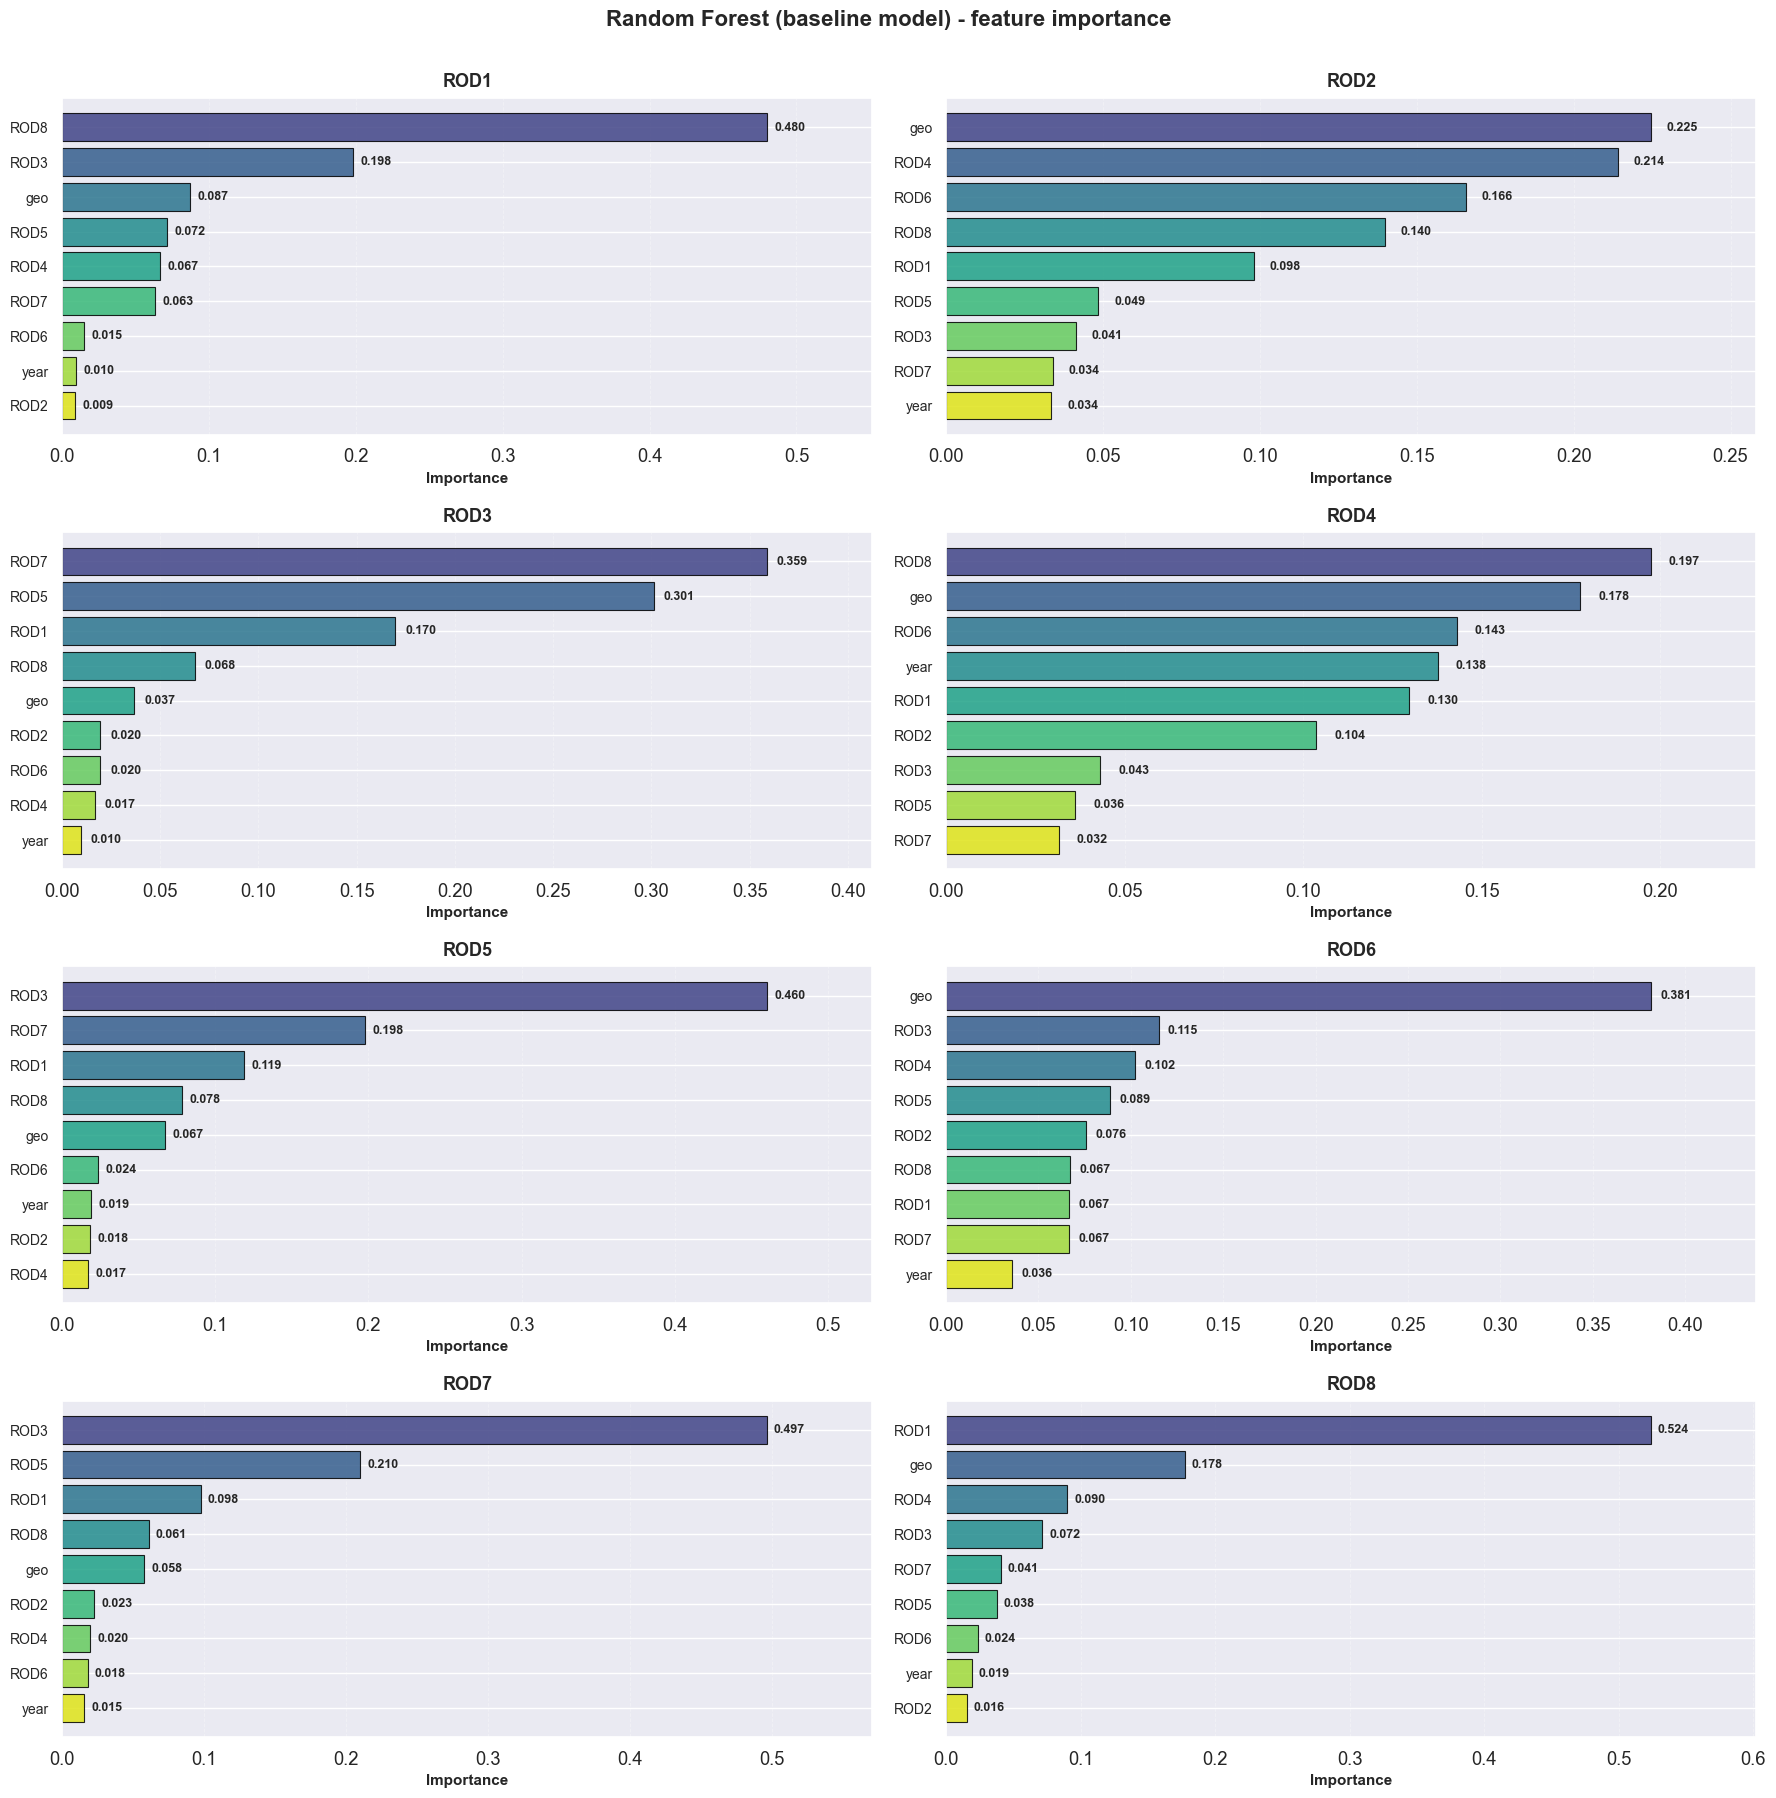

Most important predictor for each indicator:
  ROD1: ROD8 (0.480)
  ROD2: geo (0.225)
  ROD3: ROD7 (0.359)
  ROD4: ROD8 (0.197)
  ROD5: ROD3 (0.460)
  ROD6: geo (0.381)
  ROD7: ROD3 (0.497)
  ROD8: ROD1 (0.524)


In [11]:
plot_feature_importance(rf_imputer.get_feature_importance(), 'Random Forest (baseline model)', plt.cm.viridis)

## 6. XGBoost baseline model

### 6.1 Model training, five-fold cross-validation and imputation

In [12]:
# ============================================================================
# XGBOOST MODEL (BASELINE) - TRAINING, CROSS-VALIDATION AND IMPUTATION
# ============================================================================

CV_FOLDS = 5          # five-fold cross-validation
USE_HYPEROPT = False  # baseline models: no hyperparameter optimization

xgb_imputer = XGBoostImputer(
    cv_folds=CV_FOLDS,
    use_hyperopt=USE_HYPEROPT,
)
xgb_imputer.print_params()
print()

start_time = time.time()
df_imputed_xgb = xgb_imputer.fit_and_impute(df.copy())
elapsed_time = time.time() - start_time
print(f"Training time: {elapsed_time:.2f} s ({elapsed_time / 60:.2f} min)\n")

# Cross-validation results (mean ± standard deviation across the five folds)
xgb_imputer.print_cv_results()

xgb_metrics_df = xgb_imputer.get_cv_metrics_df()

XGBoost hyperparameters:
  - n_estimators: 200
  - learning_rate: 0.1
  - max_depth: 6
  - subsample: 0.8
  - colsample_bytree: 0.8
  - min_child_weight: 3
  - reg_alpha: 0.1
  - reg_lambda: 0.1
  - random_state: 42
  - cv_folds: 5
  - use_hyperopt: False



Training time: 7.56 s (0.13 min)

CROSS-VALIDATION RESULTS (5-fold CV)

OVERALL MEANS (across all indicators):
--------------------------------------------------
  R²:    0.9433 ± 0.0459
  nRMSE: 0.0351 ± 0.0124
  nMAE:  0.0232 ± 0.0088
  sMAPE: 14.17% ± 11.44%

CV RESULTS BY INDICATOR:
------------------------------------------------------------------------------------------

ROD1:
  R²:    0.9882 ± 0.0005
  nRMSE: 0.0210 ± 0.0006
  nMAE:  0.0158 ± 0.0004
  sMAPE: 1.10 ± 0.02%

ROD2:
  R²:    0.8354 ± 0.0444
  nRMSE: 0.0517 ± 0.0058
  nMAE:  0.0300 ± 0.0070
  sMAPE: 24.96 ± 1.73%

ROD3:
  R²:    0.9584 ± 0.0039
  nRMSE: 0.0372 ± 0.0024
  nMAE:  0.0264 ± 0.0016
  sMAPE: 9.99 ± 0.33%

ROD4:
  R²:    0.9456 ± 0.0040
  nRMSE: 0.0433 ± 0.0013
  nMAE:  0.0313 ± 0.0011
  sMAPE: 7.36 ± 0.35%

ROD5:
  R²:    0.9220 ± 0.0070
  nRMSE: 0.0510 ± 0.0028
  nMAE:  0.0358 ± 0.0026
  sMAPE: 12.76 ± 0.50%

ROD6:
  R²:    0.9652 ± 0.0101
  nRMSE: 0.0211 ± 0.0017
  nMAE:  0.0086 ± 0.0003
  sMAPE: 37.08 ± 

### 6.2 Feature importance analysis

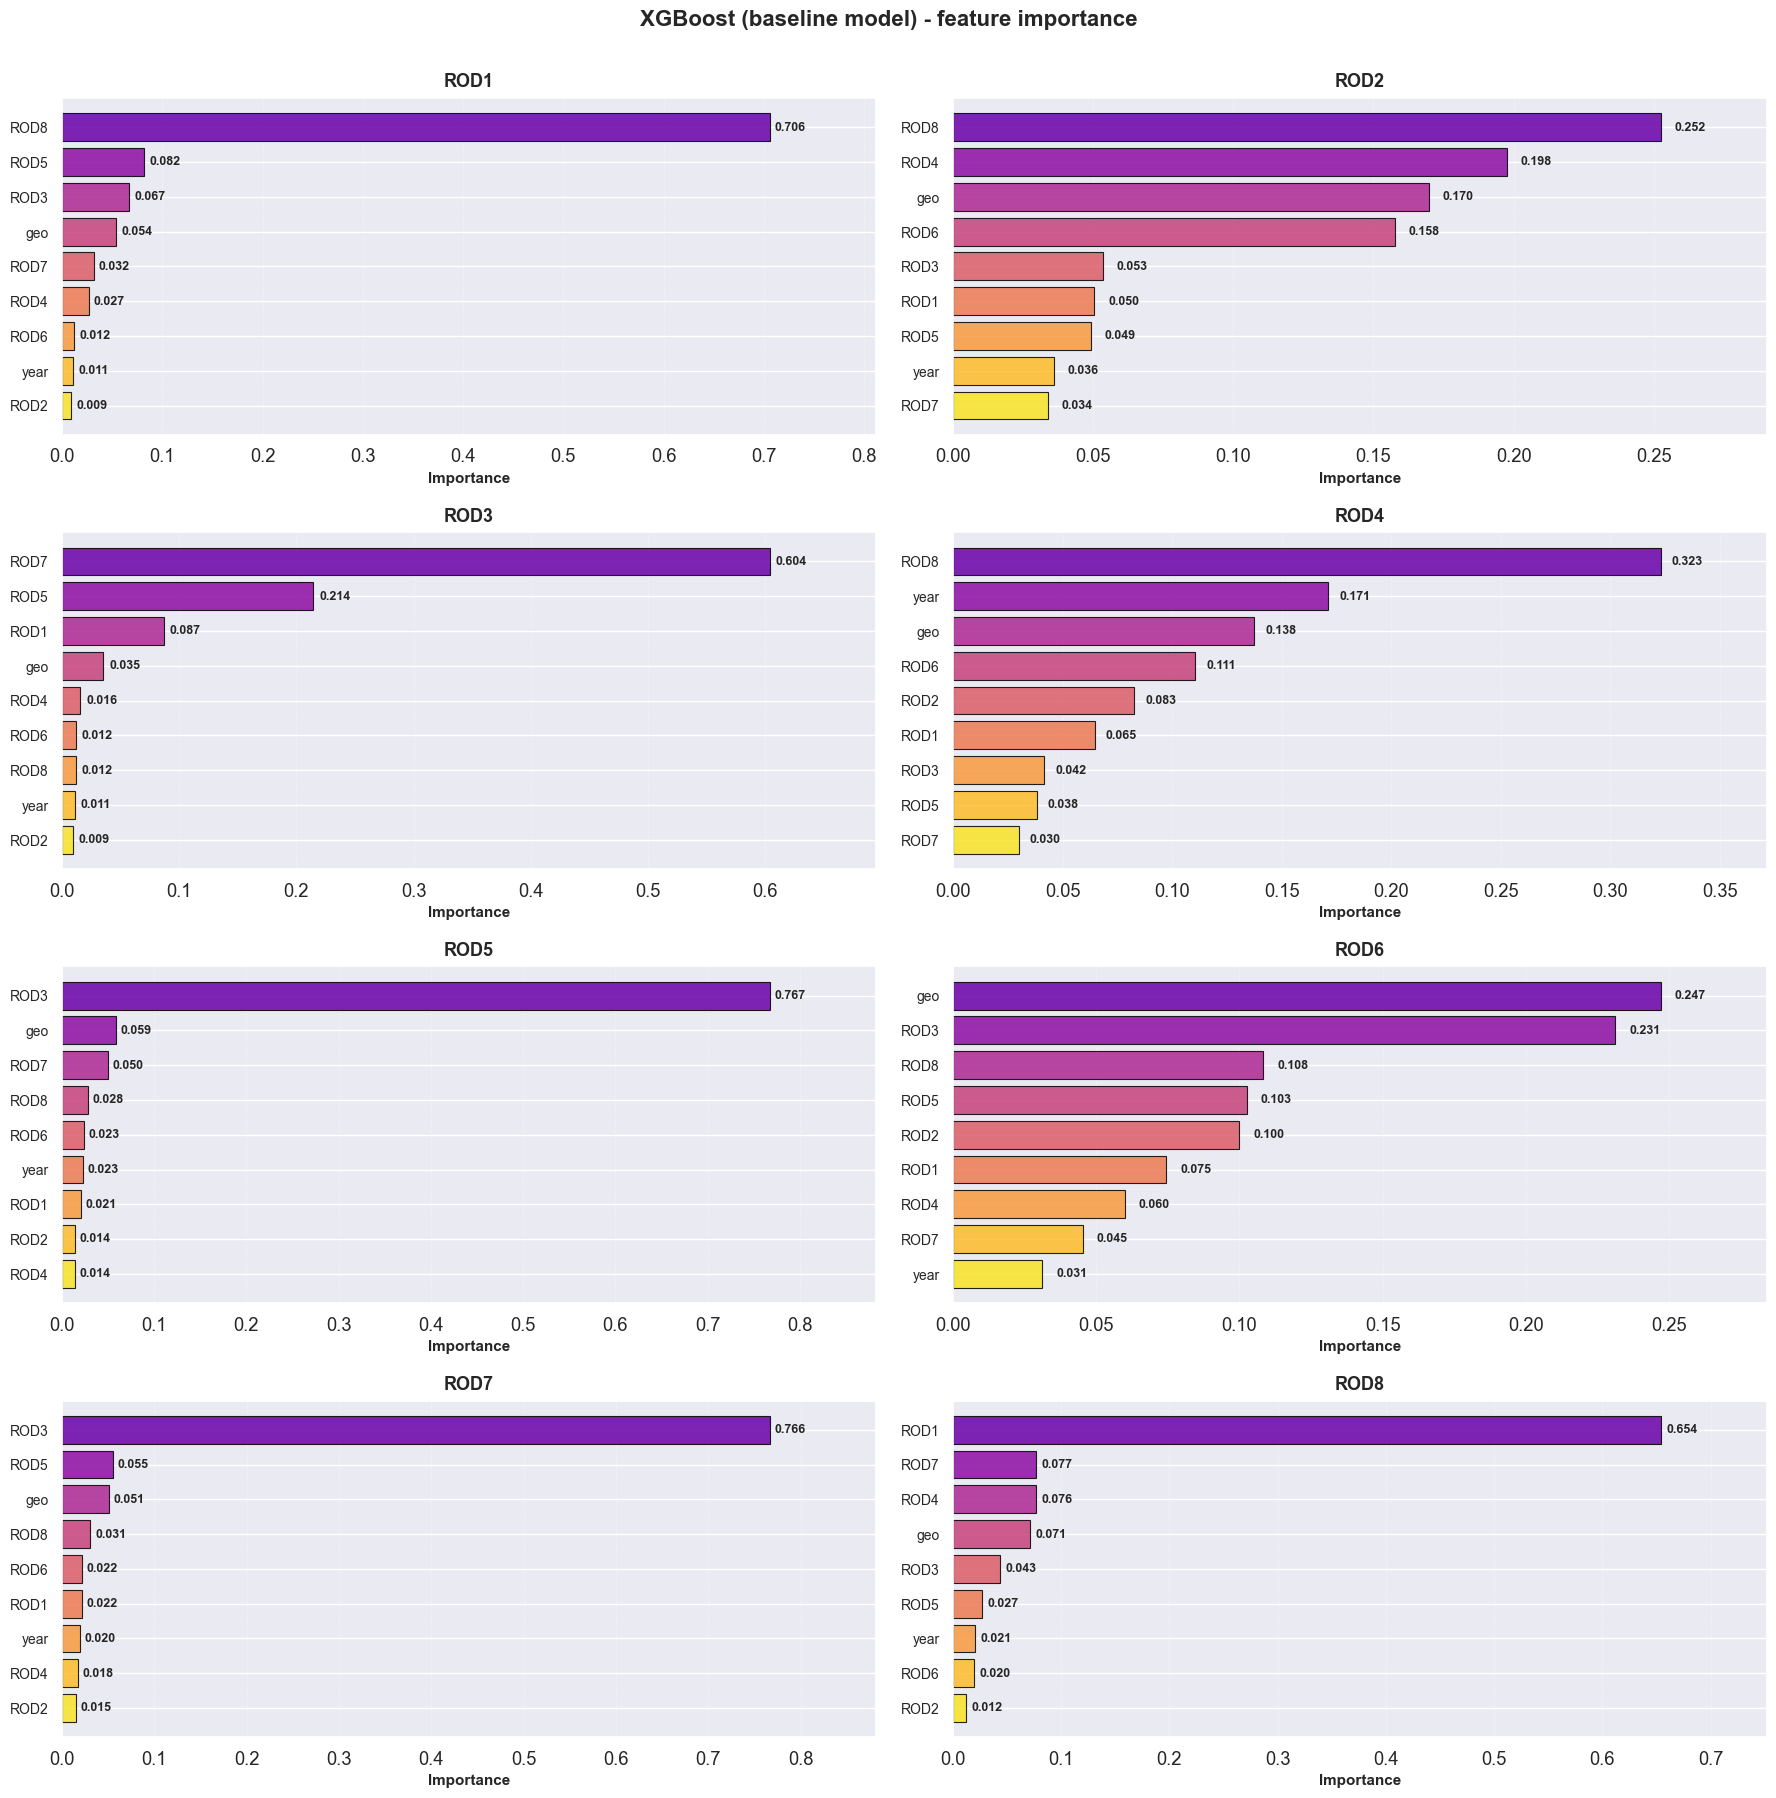

Most important predictor for each indicator:
  ROD1: ROD8 (0.706)
  ROD2: ROD8 (0.252)
  ROD3: ROD7 (0.604)
  ROD4: ROD8 (0.323)
  ROD5: ROD3 (0.767)
  ROD6: geo (0.247)
  ROD7: ROD3 (0.766)
  ROD8: ROD1 (0.654)


In [13]:
plot_feature_importance(xgb_imputer.get_feature_importance(), 'XGBoost (baseline model)', plt.cm.plasma)

## 7. Results: comparison of XGBoost and Random Forest baseline models

In [14]:
# ============================================================================
# HELPER FUNCTIONS FOR THE RESULT TABLES
# ============================================================================

def indicator_metrics_table(rf_df, xgb_df):
    """Per-indicator CV metrics (mean ± std across folds) for both models, as in Tables 2-3."""
    rf_df = rf_df.set_index('Indicator')
    xgb_df = xgb_df.set_index('Indicator')
    table = pd.DataFrame({
        ('Random Forest', 'nRMSE'): rf_df['nRMSE_formatted'],
        ('Random Forest', 'nMAE'): rf_df['nMAE_formatted'],
        ('Random Forest', 'R²'): rf_df['R²_formatted'],
        ('XGBoost', 'nRMSE'): xgb_df['nRMSE_formatted'],
        ('XGBoost', 'nMAE'): xgb_df['nMAE_formatted'],
        ('XGBoost', 'R²'): xgb_df['R²_formatted'],
    })
    table.index.name = 'Indicator ID'
    return table


def overall_metrics_table(rf_imp, xgb_imp):
    """Overall CV performance across all indicators (mean ± std), as in Tables 4-5."""
    rf_s, xgb_s = rf_imp.get_cv_summary(), xgb_imp.get_cv_summary()
    rows = [('R²', 'r2', 4), ('nRMSE', 'nrmse', 4), ('nMAE', 'nmae', 4), ('sMAPE', 'smape', 2)]
    return pd.DataFrame({
        'Metric': [label for label, _, _ in rows],
        'Random Forest (CV)': [f"{rf_s[k + '_mean']:.{d}f} ± {rf_s[k + '_std']:.{d}f}" for _, k, d in rows],
        'XGBoost (CV)': [f"{xgb_s[k + '_mean']:.{d}f} ± {xgb_s[k + '_std']:.{d}f}" for _, k, d in rows],
    })


def better_model_counts(rf_df, xgb_df):
    """Number of indicators for which each model achieves the better CV mean of each metric."""
    rf_df = rf_df.set_index('Indicator')
    xgb_df = xgb_df.set_index('Indicator')
    rows = []
    for metric, higher_is_better in [('R²', True), ('nRMSE', False), ('nMAE', False), ('sMAPE (%)', False)]:
        xgb_better = (xgb_df[metric] > rf_df[metric]) if higher_is_better else (xgb_df[metric] < rf_df[metric])
        rows.append({'Metric': metric.replace(' (%)', ''),
                     'XGBoost better': int(xgb_better.sum()),
                     'Random Forest better': int((~xgb_better).sum())})
    return pd.DataFrame(rows)

### 7.1 Performance by indicator (Table 2)

In [15]:
# ============================================================================
# TABLE 2. BASELINE RANDOM FOREST AND XGBOOST MODEL PERFORMANCE METRICS (NRMSE, NMAE, R²) USING 5-FOLD CROSS-VALIDATION
# ============================================================================

table_by_indicator = indicator_metrics_table(rf_metrics_df, xgb_metrics_df)

print("Table 2. Baseline Random Forest and XGBoost model performance metrics (nRMSE, nMAE, R²) using 5-fold cross-validation")
display(table_by_indicator)

print("Number of indicators for which each model achieves the better CV mean:")
display(better_model_counts(rf_metrics_df, xgb_metrics_df).style.hide(axis='index'))

Table 2. Baseline Random Forest and XGBoost model performance metrics (nRMSE, nMAE, R²) using 5-fold cross-validation


Random Forest                                    \
                        nRMSE             nMAE               R²   
Indicator ID                                                      
ROD1          0.0284 ± 0.0010  0.0215 ± 0.0006  0.9784 ± 0.0011   
ROD2          0.0659 ± 0.0077  0.0392 ± 0.0077  0.7316 ± 0.0662   
ROD3          0.0433 ± 0.0025  0.0314 ± 0.0018  0.9438 ± 0.0040   
ROD4          0.0666 ± 0.0014  0.0485 ± 0.0010  0.8715 ± 0.0050   
ROD5          0.0547 ± 0.0040  0.0390 ± 0.0031  0.9106 ± 0.0074   
ROD6          0.0605 ± 0.0036  0.0280 ± 0.0007  0.7229 ± 0.0246   
ROD7          0.0419 ± 0.0030  0.0272 ± 0.0018  0.9227 ± 0.0114   
ROD8          0.0261 ± 0.0017  0.0191 ± 0.0008  0.9795 ± 0.0026   

                      XGBoost                                    
                        nRMSE             nMAE               R²  
Indicator ID                                                     
ROD1          0.0210 ± 0.0006  0.0158 ± 0.0004  0.9882 ± 0.0005  
ROD2          0.0517 ± 0.0058  0.0300 ± 0.0070  0.8354 ± 0.0444  
ROD3          0.0372 ± 0.0024  0.0264 ± 0.0016  0.9584 ± 0.0039  
ROD4          0.0433 ± 0.0013  0.0313 ± 0.0011  0.9456 ± 0.0040  
ROD5          0.0510 ± 0.0028  0.0358 ± 0.0026  0.9220 ± 0.0070  
ROD6          0.0211 ± 0.0017  0.0086 ± 0.0003  0.9652 ± 0.0101  
ROD7          0.0361 ± 0.0013  0.0231 ± 0.0012  0.9429 ± 0.0048  
ROD8          0.0196 ± 0.0015  0.0143 ± 0.0009  0.9885 ± 0.0015

Number of indicators for which each model achieves the better CV mean:


Metric,XGBoost better,Random Forest better
R²,8,0
nRMSE,8,0
nMAE,8,0
sMAPE,8,0


### 7.2 Relative R² improvement of XGBoost over Random Forest

Relative improvement = (R²<sub>XGBoost</sub> − R²<sub>Random Forest</sub>) / R²<sub>Random Forest</sub> × 100%.

In [16]:
# ============================================================================
# RELATIVE R² IMPROVEMENT OF XGBOOST OVER RANDOM FOREST (BASELINE MODELS)
# ============================================================================

r2_comparison = pd.DataFrame({
    'R² Random Forest': rf_metrics_df.set_index('Indicator')['R²'],
    'R² XGBoost': xgb_metrics_df.set_index('Indicator')['R²'],
})
r2_comparison['Difference'] = r2_comparison['R² XGBoost'] - r2_comparison['R² Random Forest']
r2_comparison['Relative improvement (%)'] = r2_comparison['Difference'] / r2_comparison['R² Random Forest'] * 100
r2_comparison.index.name = 'Indicator ID'

display(r2_comparison.style.format({
    'R² Random Forest': '{:.4f}', 'R² XGBoost': '{:.4f}',
    'Difference': '{:.4f}', 'Relative improvement (%)': '{:.2f}',
}))

largest = r2_comparison['Difference'].idxmax()
print(f"Largest difference: {largest} ({INDICATORS[largest]}): "
      f"R² {r2_comparison.loc[largest, 'R² Random Forest']:.4f} -> {r2_comparison.loc[largest, 'R² XGBoost']:.4f}, "
      f"relative improvement {r2_comparison.loc[largest, 'Relative improvement (%)']:.2f}%")

,R² Random Forest,R² XGBoost,Difference,Relative improvement (%)
Indicator ID,,,,
ROD1,0.9784,0.9882,0.0098,1.00
ROD2,0.7316,0.8354,0.1039,14.20
ROD3,0.9438,0.9584,0.0146,1.55
ROD4,0.8715,0.9456,0.0741,8.51
ROD5,0.9106,0.9220,0.0113,1.25
ROD6,0.7229,0.9652,0.2423,33.51
ROD7,0.9227,0.9429,0.0202,2.19
ROD8,0.9795,0.9885,0.0090,0.92


Largest difference: ROD6 (population_density): R² 0.7229 -> 0.9652, relative improvement 33.51%


### 7.3 Overall cross-validation performance (Table 4)

The values are the means of the per-indicator cross-validation results across the eight indicators (± standard deviation across indicators).

In [17]:
# ============================================================================
# TABLE 4. OVERALL CROSS-VALIDATION PERFORMANCE OF BASELINE IMPUTATION MODELS
# ============================================================================

table_overall = overall_metrics_table(rf_imputer, xgb_imputer)

print("Table 4. Overall cross-validation performance of baseline imputation models")
display(table_overall.style.hide(axis='index'))

Table 4. Overall cross-validation performance of baseline imputation models


Metric,Random Forest (CV),XGBoost (CV)
R²,0.8826 ± 0.0956,0.9433 ± 0.0459
nRMSE,0.0484 ± 0.0150,0.0351 ± 0.0124
nMAE,0.0317 ± 0.0093,0.0232 ± 0.0088
sMAPE,20.04 ± 19.96,14.17 ± 11.44


### 7.4 Error distribution for the youth unemployment rate, ROD5 (Figure 5)

Actual vs predicted values of the youth unemployment rate (ROD5) on the test data (20% of the known values removed before training). The panel titles and annotations report the five-fold cross-validation metrics (mean ± standard deviation across folds).

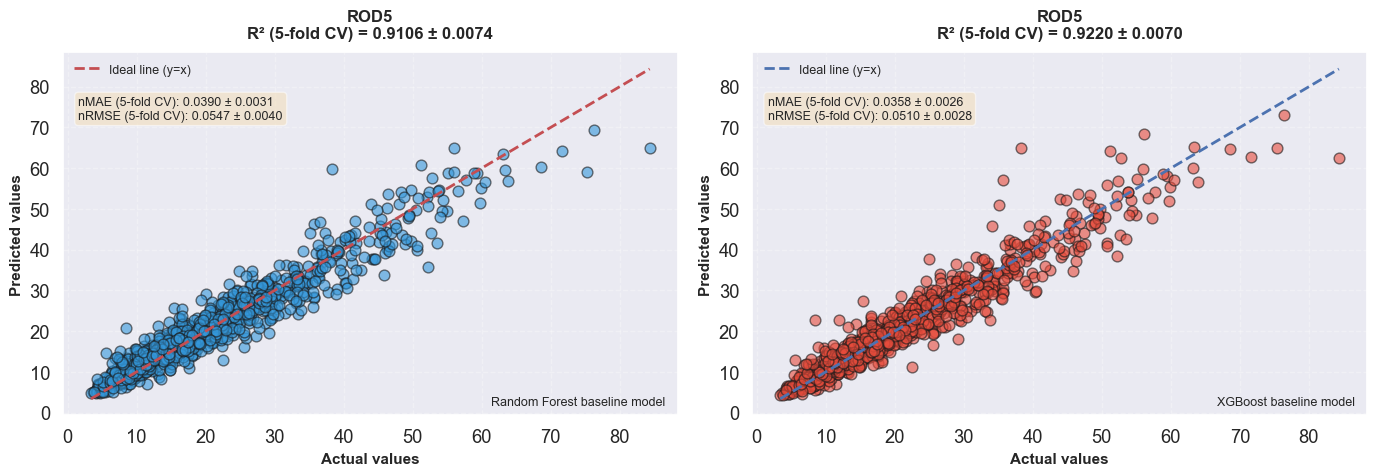

In [18]:
# ============================================================================
# FIGURE 5. nRMSE AND nMAE ERROR DISTRIBUTION (BASELINE MODELS, ROD5)
# ============================================================================

FIGURE_INDICATOR = 'ROD5'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

panels = [
    (rf_imputer, 'Random Forest baseline model', '#3498db', 'r--'),
    (xgb_imputer, 'XGBoost baseline model', '#e74c3c', 'b--'),
]

for ax, (imputer, label, color, line_style) in zip(axes, panels):
    test_data = imputer.get_test_predictions()[FIGURE_INDICATOR]
    cv = imputer.get_cv_scores()[FIGURE_INDICATOR]
    y_true, y_pred = test_data['y_true'], test_data['y_pred']

    ax.scatter(y_true, y_pred, alpha=0.6, edgecolors='k', s=60, color=color)

    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], line_style, lw=2, label='Ideal line (y=x)')

    ax.set_xlabel('Actual values', fontsize=11, fontweight='bold')
    ax.set_ylabel('Predicted values', fontsize=11, fontweight='bold')
    ax.set_title(f"{FIGURE_INDICATOR}\nR² ({CV_FOLDS}-fold CV) = {cv['r2_mean']:.4f} ± {cv['r2_std']:.4f}",
                 fontsize=12, fontweight='bold', pad=10)
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.text(0.025, 0.88,
            f"nMAE ({CV_FOLDS}-fold CV): {cv['nmae_mean']:.4f} ± {cv['nmae_std']:.4f}\n"
            f"nRMSE ({CV_FOLDS}-fold CV): {cv['nrmse_mean']:.4f} ± {cv['nrmse_std']:.4f}",
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    ax.text(0.98, 0.02, label, transform=ax.transAxes, fontsize=9, ha='right', va='bottom')

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'figure_5_rod5_baseline.png'), dpi=300, bbox_inches='tight')
plt.show()

## 8. Imputed datasets

Following the imputation process, a complete dataset of economic indicators is obtained for each model. The imputed datasets are saved to the `results/` directory.

In [19]:
# ============================================================================
# SAVING THE IMPUTED DATASETS
# ============================================================================

for model_name, df_imputed in [('random_forest', df_imputed_rf), ('xgboost', df_imputed_xgb)]:
    path = os.path.join(RESULTS_DIR, f'imputed_dataset_{model_name}_baseline.csv')
    df_imputed.to_csv(path, index=False)
    print(f"{path}: {len(df_imputed):,} rows, "
          f"missing values before = {int(df[INDICATOR_IDS].isna().sum().sum()):,}, "
          f"after = {int(df_imputed[INDICATOR_IDS].isna().sum().sum())}")

results\imputed_dataset_random_forest_baseline.csv: 6,984 rows, missing values before = 17,511, after = 0
results\imputed_dataset_xgboost_baseline.csv: 6,984 rows, missing values before = 17,511, after = 0


## 9. Saving the cross-validation metrics

The per-indicator cross-validation metrics are saved to `results/cv_metrics_baseline.csv (input for Figure 4 in Notebook 2).

In [20]:
# ============================================================================
# SAVING THE CROSS-VALIDATION METRICS
# ============================================================================

metric_cols = ['Indicator', 'R²', 'R²_std', 'nRMSE', 'nRMSE_std', 'nMAE', 'nMAE_std', 'sMAPE (%)', 'sMAPE_std', 'Sample size']

cv_metrics = pd.concat([
    rf_metrics_df[metric_cols].assign(Model='Random Forest'),
    xgb_metrics_df[metric_cols].assign(Model='XGBoost'),
])[['Model'] + metric_cols]

metrics_path = os.path.join(RESULTS_DIR, 'cv_metrics_baseline.csv')
cv_metrics.to_csv(metrics_path, index=False)
print(f"Cross-validation metrics saved: {metrics_path}")
display(cv_metrics.round(4))

Cross-validation metrics saved: results\cv_metrics_baseline.csv


,Model,Indicator,R²,R²_std,nRMSE,nRMSE_std,nMAE,nMAE_std,sMAPE (%),sMAPE_std,Sample size
0,Random Forest,ROD1,0.9784,0.0011,0.0284,0.0010,0.0215,0.0006,1.5020,0.0240,4015
1,Random Forest,ROD2,0.7316,0.0662,0.0659,0.0077,0.0392,0.0077,30.7106,1.4029,2583
2,Random Forest,ROD3,0.9438,0.0040,0.0433,0.0025,0.0314,0.0018,11.8450,0.3796,3965
3,Random Forest,ROD4,0.8715,0.0050,0.0666,0.0014,0.0485,0.0010,11.2752,0.5409,3928
4,Random Forest,ROD5,0.9106,0.0074,0.0547,0.0040,0.0390,0.0031,14.0641,0.5452,3532
5,Random Forest,ROD6,0.7229,0.0246,0.0605,0.0036,0.0280,0.0007,67.3661,1.8909,5028
6,Random Forest,ROD7,0.9227,0.0114,0.0419,0.0030,0.0272,0.0018,21.0874,0.6180,3627
7,Random Forest,ROD8,0.9795,0.0026,0.0261,0.0017,0.0191,0.0008,2.4354,0.0621,4015
0,XGBoost,ROD1,0.9882,0.0005,0.0210,0.0006,0.0158,0.0004,1.0990,0.0180,4015
1,XGBoost,ROD2,0.8354,0.0444,0.0517,0.0058,0.0300,0.0070,24.9550,1.7274,2583
